In [1]:
import os, copy, json, time, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets
from torchvision.utils import make_grid
from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure
from torchmetrics.image.fid import FrechetInceptionDistance

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

cuda NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
MODEL_NAME = "comparison"
DATA_DIR = "data"
CKPT_DIR = "checkpoints"
FIG_DIR = "figures"
RESULTS_DIR = "results"
for d in (DATA_DIR, CKPT_DIR, FIG_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

BATCH_SIZE = 128
ORIGINAL_DIM = 28 * 28

In [3]:
train_raw = datasets.FashionMNIST(DATA_DIR, train=True, download=True)
test_raw = datasets.FashionMNIST(DATA_DIR, train=False, download=True)
images = torch.cat([train_raw.data, test_raw.data]).unsqueeze(1).float() / 255.0
labels = torch.cat([train_raw.targets, test_raw.targets])
full = TensorDataset(images, labels)

n_train, n_val = int(0.8 * len(full)), int(0.1 * len(full))
n_test = len(full) - n_train - n_val
train_set, val_set, test_set = random_split(
    full, [n_train, n_val, n_test], generator=torch.Generator().manual_seed(SEED))

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
test_targets = labels[torch.tensor(test_set.indices)]
VIS_IDX = [int(torch.nonzero(test_targets == c)[0]) for c in range(10)]
x_vis = torch.stack([test_set[i][0] for i in VIS_IDX])
x_a, x_b = x_vis[1:2], x_vis[9:10]
ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
print(f"train={len(train_set)}  val={len(val_set)}  test={len(test_set)}")

train=56000  val=7000  test=7000


In [4]:
import pandas as pd

MODELS = ["vanilla_ae", "sparse_ae", "vae", "vanilla_gan", "dcgan", "ddpm"]
NAMES = {"vanilla_ae": "Vanilla AE", "sparse_ae": "Sparse AE", "vae": "VAE",
         "vanilla_gan": "Vanilla GAN", "dcgan": "DCGAN", "ddpm": "DDPM"}
results = {}
for m in MODELS + ["mlp_classifier"]:
    with open(os.path.join(RESULTS_DIR, f"{m}.json")) as f:
        results[m] = json.load(f)
outputs = {m: torch.load(os.path.join(RESULTS_DIR, f"{m}_outputs.pt"), weights_only=True)
           for m in MODELS + ["mlp_classifier"]}


def to_grid(images, nrow):
    return make_grid(images.clamp(0, 1), nrow=nrow, padding=2, pad_value=1.0).permute(1, 2, 0).numpy()


def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), dpi=300, bbox_inches="tight")
    plt.show()


def image_rows(rows, nrow, title, filename, width=10):
    fig, axes = plt.subplots(len(rows), 1, figsize=(width, 1.15 * len(rows)))
    for ax, (label, images) in zip(axes, rows):
        ax.imshow(to_grid(images, nrow))
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_ylabel(label, rotation=0, ha="right", va="center", fontsize=10)
    fig.suptitle(title)
    fig.tight_layout()
    save_fig(fig, filename)

In [5]:
LATENT = {"vanilla_ae": "64", "sparse_ae": "64 / 256 (sparse)", "vae": "64",
          "vanilla_gan": "100 (noise)", "dcgan": "100 (noise)", "ddpm": "28x28"}
STABILITY = {"vanilla_ae": "Stabil / Konvergen", "sparse_ae": "Stabil / Konvergen", "vae": "Stabil / Konvergen",
             "vanilla_gan": "Rentan osilasi / mode collapse", "dcgan": "Cukup stabil (sensitif arsitektur)",
             "ddpm": "Sangat stabil"}
table = pd.DataFrame([{
    "Model": NAMES[m],
    "Latent dim": LATENT[m],
    "Train time / epoch (s)": results[m]["train_time_per_epoch_s"],
    "Latency (ms / 64)": results[m]["latency_ms_batch64"],
    "Test MSE": results[m]["test_mse"],
    "Test PSNR (dB)": results[m]["test_psnr"],
    "Test SSIM": results[m]["test_ssim"],
    "FID": results[m]["fid"],
    "Stability": STABILITY[m],
} for m in MODELS]).round(4)
table.to_csv(os.path.join(RESULTS_DIR, "metrics_table.csv"), index=False)
table

,Model,Latent dim,Train time / epoch (s),Latency (ms / 64),Test MSE,Test PSNR (dB),Test SSIM,FID,Stability
0,Vanilla AE,64,0.9314,0.1352,0.0066,21.8285,0.8641,NaN,Stabil / Konvergen
1,Sparse AE,64 / 256 (sparse),1.0489,0.2609,0.0144,18.4284,0.7432,NaN,Stabil / Konvergen
2,VAE,64,1.4843,0.1004,0.0131,18.8398,0.7680,88.6963,Stabil / Konvergen
3,Vanilla GAN,100 (noise),2.0656,0.2051,NaN,NaN,NaN,126.2545,Rentan osilasi / mode collapse
4,DCGAN,100 (noise),4.8187,1.2430,NaN,NaN,NaN,21.8531,Cukup stabil (sensitif arsitektur)
5,DDPM,28x28,23.1855,7254.1159,NaN,NaN,NaN,17.3371,Sangat stabil


In [6]:
mlp = results["mlp_classifier"]
ae = results["vanilla_ae"]
mlp_table = pd.DataFrame([
    {"Method": "W^T projection of z_MLP", **{k: mlp["transpose_projection"][k] for k in ("test_mse", "test_psnr", "test_ssim")}},
    {"Method": "Frozen z_MLP decoder", **{k: mlp["frozen_decoder"][k] for k in ("test_mse", "test_psnr", "test_ssim")}},
    {"Method": "Vanilla AE z_AE", **{k: ae[k] for k in ("test_mse", "test_psnr", "test_ssim")}},
]).round(4)
print(f"MLP test accuracy: {mlp['test_accuracy']:.4f} | FID of MLP-latent samples: {mlp['prior_sampling_fid']:.2f}")
mlp_table.to_csv(os.path.join(RESULTS_DIR, "mlp_limitation_table.csv"), index=False)
mlp_table

MLP test accuracy: 0.8877 | FID of MLP-latent samples: 148.22


,Method,test_mse,test_psnr,test_ssim
0,W^T projection of z_MLP,0.2824,5.4915,0.0578
1,Frozen z_MLP decoder,0.0166,17.8020,0.7213
2,Vanilla AE z_AE,0.0066,21.8285,0.8641


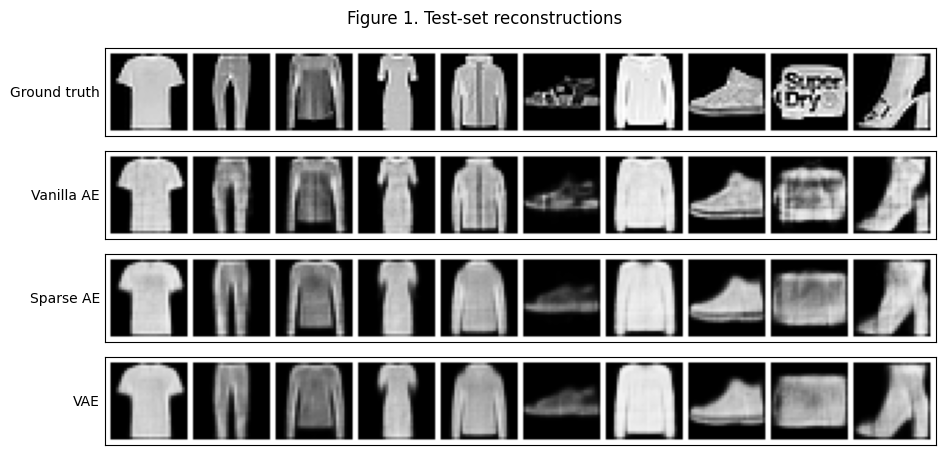

In [7]:
image_rows([("Ground truth", x_vis),
            ("Vanilla AE", outputs["vanilla_ae"]["recon"]),
            ("Sparse AE", outputs["sparse_ae"]["recon"]),
            ("VAE", outputs["vae"]["recon"])],
           nrow=10, title="Figure 1. Test-set reconstructions", filename="figure1_reconstruction.png")

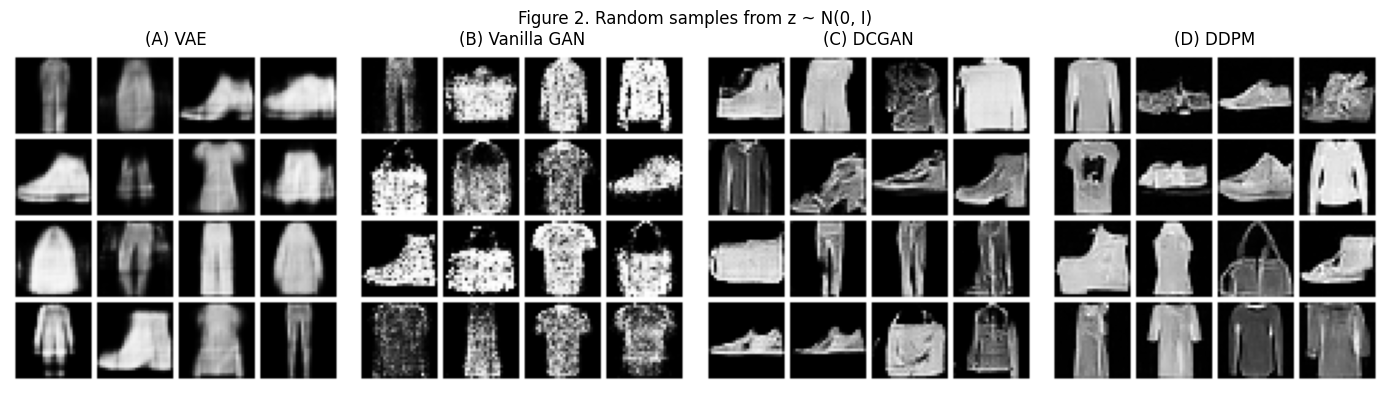

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, m, panel in zip(axes, ["vae", "vanilla_gan", "dcgan", "ddpm"], "ABCD"):
    ax.imshow(to_grid(outputs[m]["samples"][:16], nrow=4))
    ax.set_title(f"({panel}) {NAMES[m]}")
    ax.axis("off")
fig.suptitle("Figure 2. Random samples from z ~ N(0, I)")
fig.tight_layout()
save_fig(fig, "figure2_sampling.png")

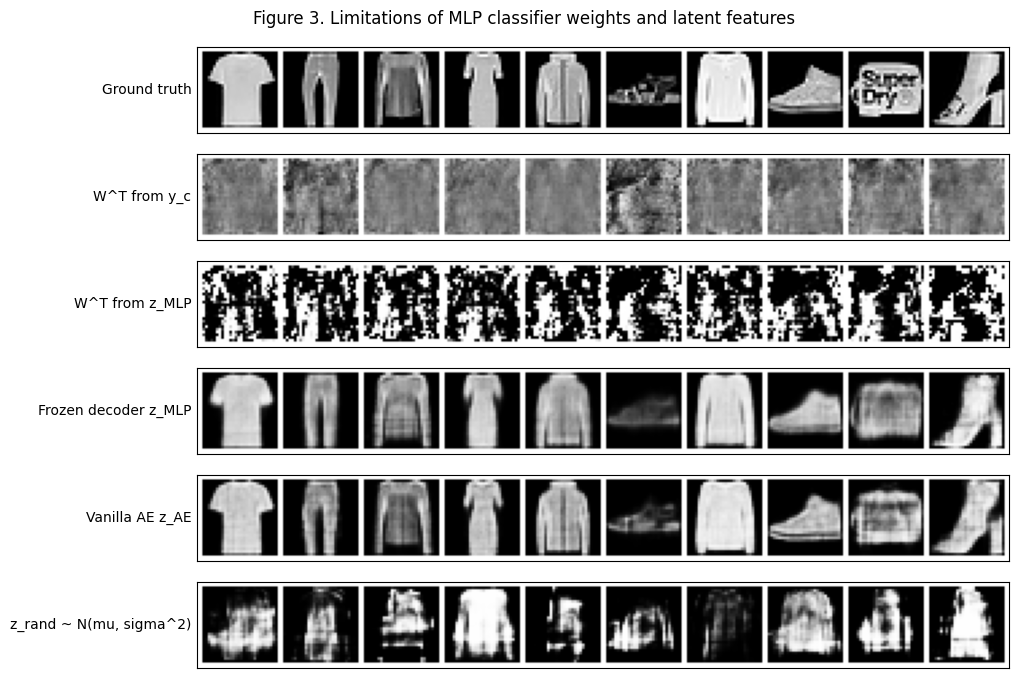

In [9]:
o = outputs["mlp_classifier"]
image_rows([("Ground truth", x_vis),
            ("W^T from y_c", o["class_proj"]),
            ("W^T from z_MLP", o["latent_proj"]),
            ("Frozen decoder z_MLP", o["frozen_recon"]),
            ("Vanilla AE z_AE", outputs["vanilla_ae"]["recon"]),
            ("z_rand ~ N(mu, sigma^2)", o["prior_samples"][:10])],
           nrow=10, title="Figure 3. Limitations of MLP classifier weights and latent features",
           filename="figure3_mlp_limitations.png")

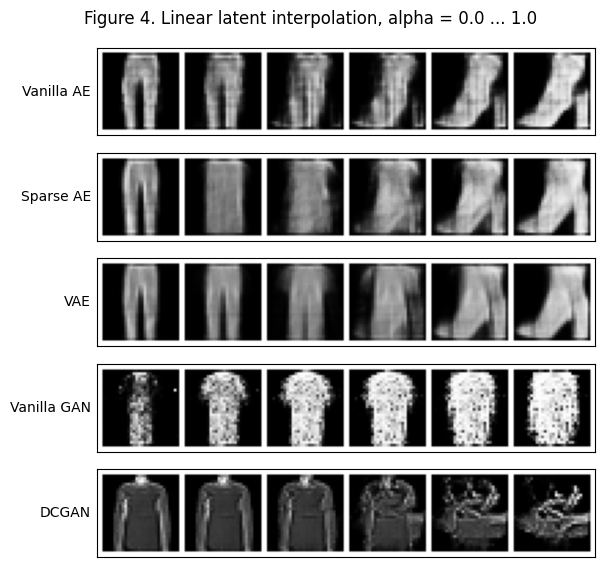

In [10]:
image_rows([(NAMES[m], outputs[m]["interp"]) for m in ["vanilla_ae", "sparse_ae", "vae", "vanilla_gan", "dcgan"]],
           nrow=len(ALPHAS), title="Figure 4. Linear latent interpolation, alpha = 0.0 ... 1.0",
           filename="figure4_interpolation.png", width=6)

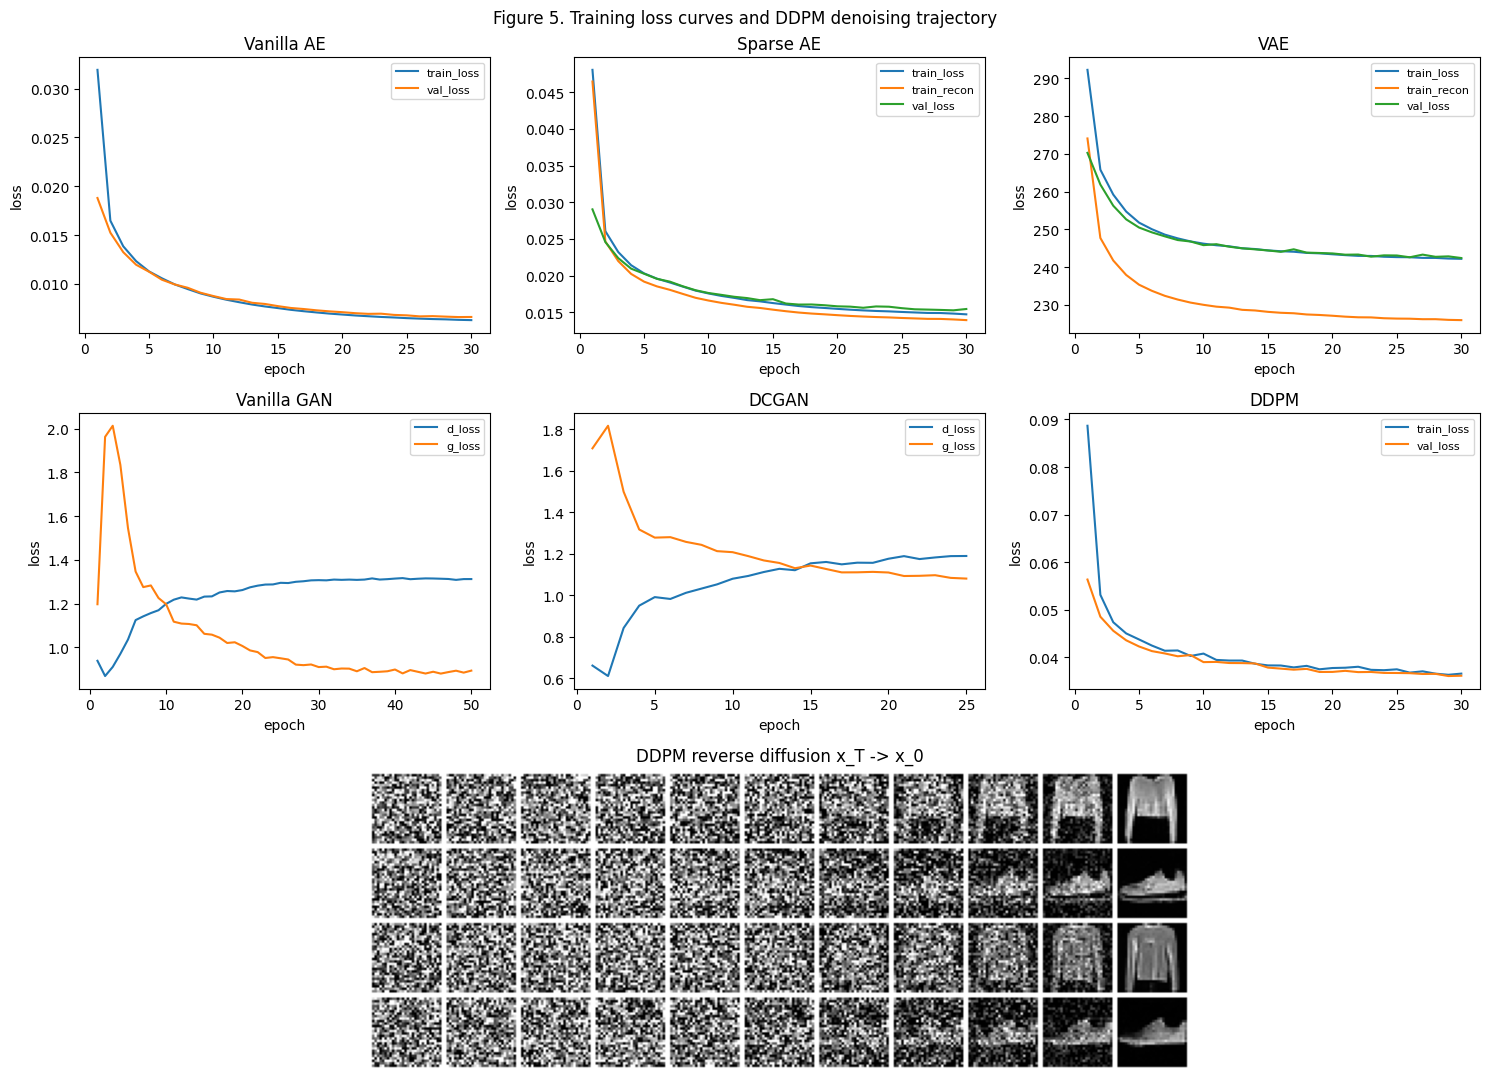

In [11]:
fig = plt.figure(figsize=(15, 11))
grid = fig.add_gridspec(3, 3, height_ratios=[1, 1, 1.1])
for i, m in enumerate(MODELS):
    ax = fig.add_subplot(grid[i // 3, i % 3])
    history = results[m]["loss_history"]
    for k, v in history.items():
        if "loss" in k or "recon" in k:
            ax.plot(range(1, len(v) + 1), v, label=k)
    ax.set_title(NAMES[m])
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss")
    ax.legend(fontsize=8)

trajectory = outputs["ddpm"]["trajectory"]
ax = fig.add_subplot(grid[2, :])
ax.imshow(to_grid(trajectory.transpose(0, 1).reshape(-1, 1, 28, 28), nrow=trajectory.shape[0]))
ax.set_title("DDPM reverse diffusion x_T -> x_0")
ax.axis("off")
fig.suptitle("Figure 5. Training loss curves and DDPM denoising trajectory")
fig.tight_layout()
save_fig(fig, "figure5_loss_ddpm.png")